In [64]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
import scipy as sp

# Question 1

Consider buying **April S&P E-mini futures** (or the nearest available contract).

- **Entry condition:** A moving average crossover should signal a buy.
  - Fast moving average: **10 minutes**
  - Slow moving average: **20 minutes**
- **Exit strategy:** Once bought, create a stop-loss exit strategy.
  - **Profit-taking price:** 30 ticks above the buying price.
  - **Stop-loss price:** Calculated using the stop-loss model built in class, with a probability of **0.55** for an up move of one tick.

Submit your ADL diagram.

In [65]:
#pull 1-minute ES futures
es = yf.Ticker("ES=F")

# Get the data
es_data = es.history(period="1d", interval="1m")

# Display the data
print(es_data)

                              Open     High      Low    Close  Volume  \
Datetime                                                                
2026-11-09 00:00:00-05:00  7447.00  7447.00  7444.25  7444.25       0   
2026-11-09 00:01:00-05:00  7444.25  7444.25  7440.50  7441.00     282   
2026-11-09 00:02:00-05:00  7440.00  7441.00  7439.00  7440.00     316   
2026-11-09 00:03:00-05:00  7440.00  7440.50  7439.25  7440.00     190   
2026-11-09 00:04:00-05:00  7440.00  7440.50  7439.25  7439.50     107   
...                            ...      ...      ...      ...     ...   
2026-11-09 13:41:00-05:00  7569.75  7570.50  7568.75  7569.25    1266   
2026-11-09 13:42:00-05:00  7569.50  7571.75  7569.25  7571.00    1328   
2026-11-09 13:43:00-05:00  7571.00  7572.75  7570.50  7572.50    1147   
2026-11-09 13:44:00-05:00  7572.50  7573.75  7571.75  7572.00    1698   
2026-11-09 13:45:00-05:00  7572.00  7573.50  7571.50  7571.75    1707   

                           Dividends  Stock Splits

In [66]:
#calculate moving avgs

fast_t = es_data['Close'].rolling(window=10).mean()
slow_t = es_data['Close'].rolling(window=20).mean()

buy_signals = (fast_t > slow_t) & (fast_t.shift(1) <= slow_t.shift(1))

#we want E to represent the first bar with a buy signal, so we will use the index of the first True value in buy_signals
if buy_signals.any():
    entry_time = buy_signals.idxmax()
    E = es_data.loc[entry_time, 'Close']
else:
    print("No buy signals found.")
    E = None

#stop loss size
r = 0.45/0.55
tick_size = 0.25  # ES futures tick size

alpha = 0.05
L = int(np.ceil(np.log(alpha)/np.log(r)))


#check if the exact probability of being stopped out is about alpha
prob_stop = (r**L - r**(L+30)) / (1 - r**(L+30))
prob_target = 1 - prob_stop
print(f"Probability of being stopped out: {prob_stop:.2f}")
print(f"Probability of reaching the target: {prob_target:.2f}")

#calculat exit prices
TP = E + 30 * tick_size
SL = E - L * tick_size

#simulate the trade
exit_price = None
for t, row in es_data.loc[entry_time:].iloc[1:].iterrows():
    if row['Low'] <= SL:
        print(f"Stopped out at {SL} on {row.name}")
        break
    elif row['High'] >= TP:
        print(f"Target reached at {TP} on {row.name}")
        break

#profit and loss
if exit_price is None:
    exit_price, exit_time = es_data['Close'].iloc[-1], es_data.index[-1]
ticks = (exit_price - E) / tick_size
dollars = ticks * 50  # ES futures contract multiplier

#printed summary of ticks, dollars, P(stop), P(target), E, TP, SL
print(f"Entry Price (E): {E}")
print(f"Target Price (TP): {TP}")
print(f"Stop Loss Price (SL): {SL}")
print(f"Ticks: {ticks:.2f}")
print(f"Dollars: {dollars:.2f}")
print(f"Probability of being stopped out: {prob_stop:.2f}")
print(f"Probability of reaching the target: {prob_target:.2f}")

Probability of being stopped out: 0.05
Probability of reaching the target: 0.95
Stopped out at 7437.5 on 2026-11-09 00:28:00-05:00
Entry Price (E): 7441.25
Target Price (TP): 7448.75
Stop Loss Price (SL): 7437.5
Ticks: 522.00
Dollars: 26100.00
Probability of being stopped out: 0.05
Probability of reaching the target: 0.95


### Question 1 ADL diagram

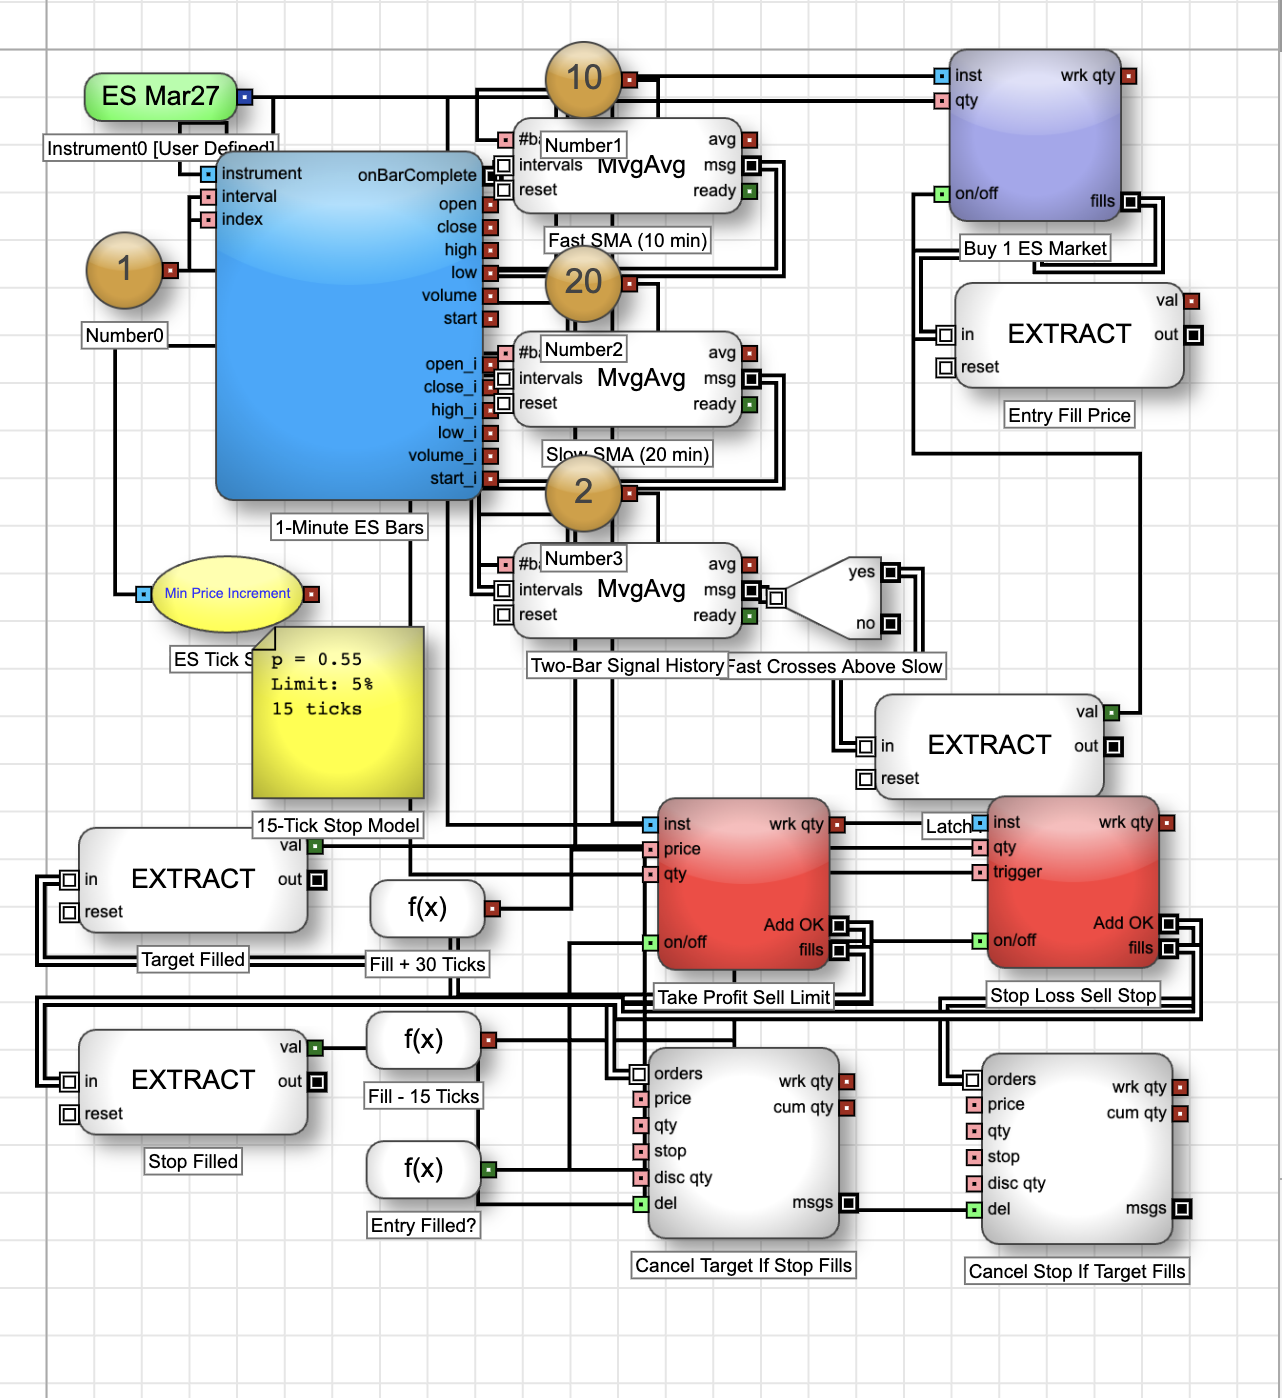

### ADL strategy execution note

The 10-minute moving average must cross **upward** through the 20-minute moving average before a new buy order is submitted. For the example shown in the original output, the entry is 7441.25, the 30-tick target is 7448.75, and the 15-tick stop is 7437.50. After entry fills, place a sell limit order at the target and a sell stop-market order at the stop with one-cancels-other (OCO) handling.

### Question 1 — Corrected trade P&L (additional cell; original code and outputs preserved)

The previous simulation prints the stop being hit but does not assign `exit_price` before calculating P&L. This additional cell fixes the accounting independently without altering the original code.

In [ ]:
# Corrected exit and P&L for the existing Question 1 first entry
if buy_signals.any():
    q1_entry_time = buy_signals.idxmax()
    q1_entry = float(es_data.loc[q1_entry_time, "Close"])
    q1_target = q1_entry + 30 * 0.25
    q1_stop = q1_entry - L * 0.25
    q1_exit_price = None
    q1_exit_time = None
    q1_reason = "End of sample"

    for q1_time, q1_bar in es_data.loc[q1_entry_time:].iloc[1:].iterrows():
        if q1_bar["Low"] <= q1_stop:
            q1_exit_price = q1_stop
            q1_exit_time = q1_time
            q1_reason = "Stop loss"
            break
        elif q1_bar["High"] >= q1_target:
            q1_exit_price = q1_target
            q1_exit_time = q1_time
            q1_reason = "Profit target"
            break

    if q1_exit_price is None:
        q1_exit_price = float(es_data["Close"].iloc[-1])
        q1_exit_time = es_data.index[-1]

    q1_ticks = (q1_exit_price - q1_entry) / 0.25
    q1_pnl = q1_ticks * 12.50  # $12.50 per ES tick per contract
    print(f"Entry: {q1_entry:.2f} | Target: {q1_target:.2f} | Stop: {q1_stop:.2f}")
    print(f"Exit: {q1_exit_price:.2f} at {q1_exit_time} ({q1_reason})")
    print(f"P&L: {q1_ticks:.0f} ticks / ${q1_pnl:.2f} for 1 contract")
else:
    print("No buy signal found in the sample.")

**Question 1 interpretation:** The model sets a 30-tick take-profit and chooses the stop-loss distance from an assumed independent-tick random walk with probability 0.55 of an upward tick. For the sample entry shown in the original notebook, the 15-tick stop was reached first, corresponding to **−15 ticks or −$187.50 for one ES contract**, before fees/slippage. The model probabilities are theoretical assumptions, not observed win rates. Historical bar simulation assumes fills at specified levels.

# Question 2

Consider **selling E-mini S&P 500 futures** when the price is at or above the upper Bollinger Band (20 bars, two standard deviations) **and** the 14-period RSI is over 80. Buy back once price returns to the middle Bollinger Band. Re-arm the algorithm to repeat this strategy after every completed trade. Submit an ADL diagram.

**Strategy logic diagram (ADL blueprint, not a screenshot from TT Algo Design Lab)**

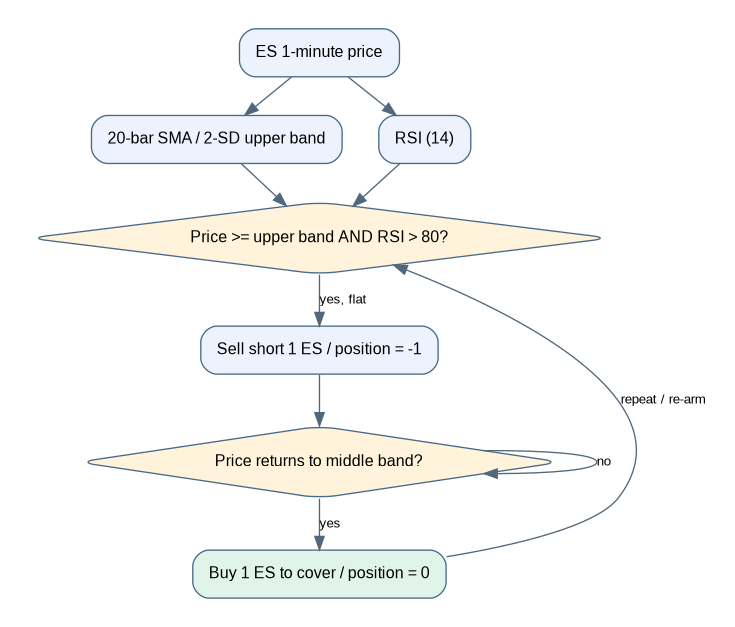

Use a **flat-position check** on the sell signal, then wait for the buyback fill before re-arming. This state-based loop is preferable to a fixed-iteration loop that might submit duplicate orders.

In [ ]:
# Question 2: Bollinger Bands + RSI short strategy
# Using 1-minute continuous ES futures data for a historical example
es_q2 = yf.Ticker("ES=F").history(period="5d", interval="1m")
es_q2 = es_q2[["Open", "High", "Low", "Close"]].copy()

# Bollinger Bands: 20-period average, 2 population standard deviations
es_q2["Middle"] = es_q2["Close"].rolling(20).mean()
es_q2["STD"] = es_q2["Close"].rolling(20).std(ddof=0)
es_q2["Upper"] = es_q2["Middle"] + 2 * es_q2["STD"]
es_q2["Lower"] = es_q2["Middle"] - 2 * es_q2["STD"]

# RSI (14 periods, Wilder-style exponential smoothing)
q2_change = es_q2["Close"].diff()
q2_gain = q2_change.clip(lower=0)
q2_loss = -q2_change.clip(upper=0)
q2_avg_gain = q2_gain.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
q2_avg_loss = q2_loss.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
q2_rs = q2_avg_gain / q2_avg_loss
es_q2["RSI"] = 100 - 100 / (1 + q2_rs)
es_q2.loc[(q2_avg_loss == 0) & (q2_avg_gain > 0), "RSI"] = 100
es_q2.loc[(q2_avg_loss == 0) & (q2_avg_gain == 0), "RSI"] = 50

es_q2["Sell_Signal"] = (es_q2["Close"] >= es_q2["Upper"]) & (es_q2["RSI"] > 80)

# A position flag prevents duplicate shorts; closing the trade re-arms the entry
q2_position = 0
q2_entry_price = None
q2_entry_time = None
q2_trades = []

for q2_time, q2_bar in es_q2.dropna().iterrows():
    if q2_position == 0:
        if q2_bar["Sell_Signal"]:
            q2_position = -1
            q2_entry_price = float(q2_bar["Close"])
            q2_entry_time = q2_time
    elif q2_bar["Close"] <= q2_bar["Middle"]:
        q2_exit = float(q2_bar["Close"])
        q2_ticks = (q2_entry_price - q2_exit) / 0.25
        q2_trades.append({
            "Entry Time": q2_entry_time,
            "Exit Time": q2_time,
            "Entry": q2_entry_price,
            "Exit": q2_exit,
            "Ticks": q2_ticks,
            "PnL ($)": q2_ticks * 12.50
        })
        q2_position = 0
        q2_entry_price = None
        q2_entry_time = None

q2_results = pd.DataFrame(q2_trades)
print("Question 2: Bollinger Bands / RSI Short")
print("Completed trades:", len(q2_results))
if len(q2_results):
    print(q2_results.to_string(index=False))
    print(f"Total P&L: ${q2_results['PnL ($)'].sum():.2f}")
    print(f"Win rate: {(q2_results['PnL ($)'] > 0).mean()*100:.2f}%")
else:
    print("No completed trades in this historical sample.")
print("Open short at end of sample:", q2_position == -1)

plt.figure(figsize=(14, 6))
plt.plot(es_q2.index, es_q2["Close"], label="ES Close", linewidth=1)
plt.plot(es_q2.index, es_q2["Middle"], label="Middle Band")
plt.plot(es_q2.index, es_q2["Upper"], label="Upper Band", linestyle="--")
plt.plot(es_q2.index, es_q2["Lower"], label="Lower Band", linestyle="--")
q2_signals = es_q2[es_q2["Sell_Signal"]]
plt.scatter(q2_signals.index, q2_signals["Close"], marker="v", color="red", s=15, label="Sell conditions")
plt.title("Question 2: Bollinger Bands and RSI")
plt.xlabel("Time")
plt.ylabel("ES Futures Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

This strategy looks for potentially overbought prices using **two simultaneous indicators**: the price reaching the upper Bollinger Band (20-period mean plus two standard deviations) and a 14-period RSI above 80. When both occur and the account is flat, the algorithm sells one ES contract short. It buys the contract back once the price returns to or below the middle Bollinger Band, then begins looking for another entry. The idea is **mean reversion**: extreme price moves sometimes reverse toward a recent average. Using both indicators may reduce some false signals, but a strong uptrend can remain overbought and lead to large short losses.

**Testing assumptions:** Trades are entered and exited at one-minute bar closing prices, without commissions, spreads, or slippage; the position is not marked to market at the end of the sample if still open. The chart marks indicator conditions, not necessarily actual executed short entries. A live ADL implementation should check fills and avoid repeated orders while a position is already open. **A screenshot of the actual TT ADL layout is still needed** because the diagram above is a conceptual blueprint.

# Question 3

**Original algorithm: Volatility-adjusted breakout.** Enter long if the current close exceeds the highest high of the previous 20 one-minute bars, provided the close is also above its 50-minute simple moving average. Risk management uses the 14-minute average true range (ATR): exit at two ATR below entry or three ATR above entry, whichever is reached first.

### Question 3 ADL diagram

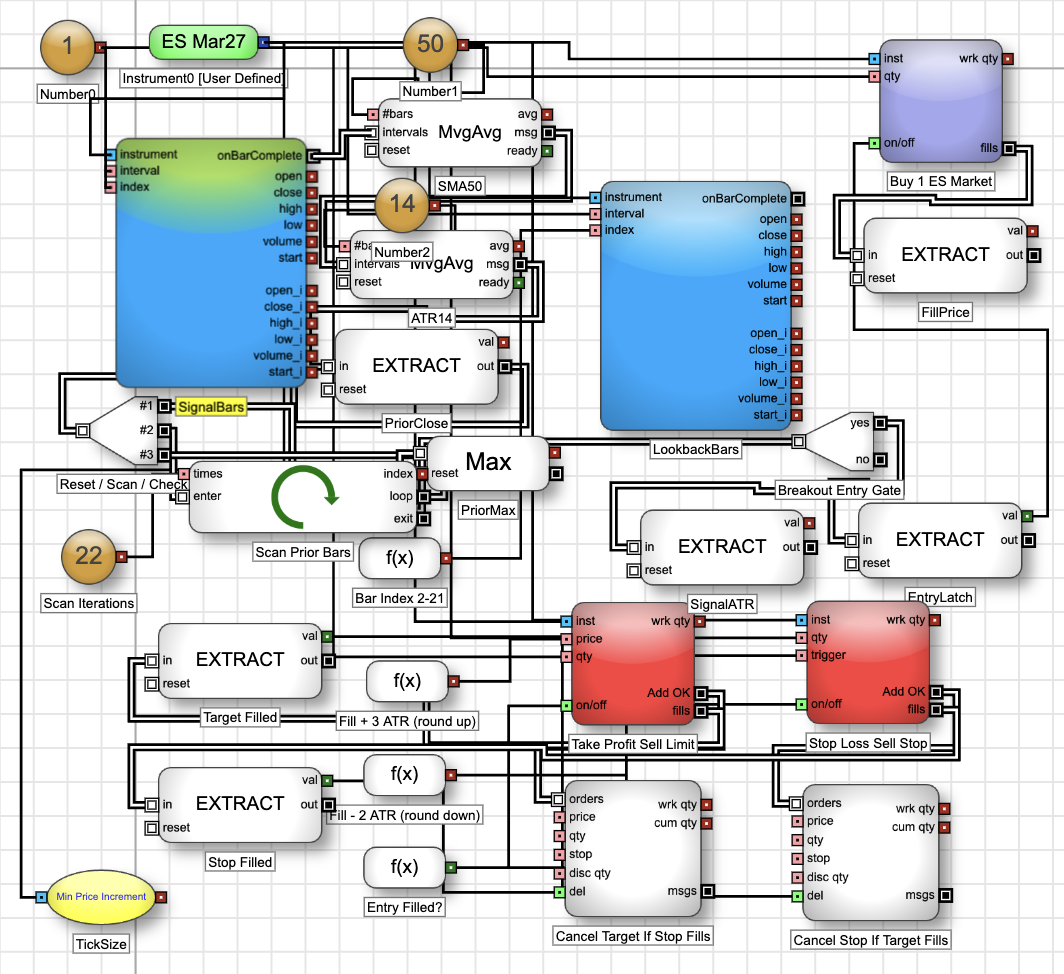

In [ ]:
# Question 3: Original volatility-adjusted breakout strategy
es_q3 = yf.Ticker("ES=F").history(period="5d", interval="1m")
es_q3 = es_q3[["Open", "High", "Low", "Close"]].copy()

es_q3["SMA50"] = es_q3["Close"].rolling(50).mean()
es_q3["Previous_High"] = es_q3["High"].rolling(20).max().shift(1)

q3_prior_close = es_q3["Close"].shift(1)
q3_true_range = pd.concat([
    es_q3["High"] - es_q3["Low"],
    (es_q3["High"] - q3_prior_close).abs(),
    (es_q3["Low"] - q3_prior_close).abs()
], axis=1).max(axis=1)
es_q3["ATR"] = q3_true_range.rolling(14).mean()

es_q3["Buy_Signal"] = ((es_q3["Close"] > es_q3["Previous_High"]) &
                        (es_q3["Close"] > es_q3["SMA50"]))

q3_position = 0
q3_entry = None
q3_entry_time = None
q3_stop = None
q3_target = None
q3_trades = []

for q3_time, q3_bar in es_q3.dropna().iterrows():
    if q3_position == 0:
        if q3_bar["Buy_Signal"]:
            q3_position = 1
            q3_entry = float(q3_bar["Close"])
            q3_entry_time = q3_time
            q3_stop = np.floor((q3_entry - 2 * q3_bar["ATR"]) / 0.25) * 0.25
            q3_target = np.ceil((q3_entry + 3 * q3_bar["ATR"]) / 0.25) * 0.25
    else:
        q3_exit = None
        q3_reason = None
        if q3_bar["Low"] <= q3_stop:
            q3_exit = q3_stop
            q3_reason = "Stop loss"
        elif q3_bar["High"] >= q3_target:
            q3_exit = q3_target
            q3_reason = "Profit target"

        if q3_exit is not None:
            q3_ticks = (q3_exit - q3_entry) / 0.25
            q3_trades.append({
                "Entry Time": q3_entry_time,
                "Exit Time": q3_time,
                "Entry": q3_entry,
                "Exit": q3_exit,
                "Exit Reason": q3_reason,
                "Ticks": q3_ticks,
                "PnL ($)": q3_ticks * 12.50
            })
            q3_position = 0
            q3_entry = None
            q3_entry_time = None

q3_results = pd.DataFrame(q3_trades)
print("Question 3: Volatility-Adjusted Breakout")
print("Completed trades:", len(q3_results))
if len(q3_results):
    print(q3_results.to_string(index=False))
    print(f"Total P&L: ${q3_results['PnL ($)'].sum():.2f}")
    print(f"Win rate: {(q3_results['PnL ($)'] > 0).mean()*100:.2f}%")
    print(f"Average completed-trade P&L: ${q3_results['PnL ($)'].mean():.2f}")
else:
    print("No completed trades in this historical sample.")
print("Open long at end of sample:", q3_position == 1)

plt.figure(figsize=(14, 6))
plt.plot(es_q3.index, es_q3["Close"], label="ES Close", linewidth=1)
plt.plot(es_q3.index, es_q3["SMA50"], label="50-Minute SMA")
plt.plot(es_q3.index, es_q3["Previous_High"], label="Previous 20-Bar High", linestyle="--")
if len(q3_results):
    plt.scatter(q3_results["Entry Time"], q3_results["Entry"], marker="^", color="green", label="Buy")
    plt.scatter(q3_results["Exit Time"], q3_results["Exit"], marker="v", color="red", label="Exit")
plt.title("Question 3: Volatility-Adjusted Breakout")
plt.xlabel("Time")
plt.ylabel("ES Futures Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Why this strategy could be effective

We designed a **volatility-adjusted breakout strategy** that enters after prices rise above the highest high of the previous 20 minutes, but only if the current price is also above the 50-minute moving average. A breakout may signal increased buying pressure, and the trend filter reduces entries that go against the recent direction of the market. Rather than setting the same dollar stop on every trade, we use the 14-period ATR to adapt exit distances to current price volatility. Our stop is set two ATR below entry and the profit target is three ATR above entry, giving an intended reward-to-risk ratio of approximately **1.5:1**.

We believe combining a price breakout, a trend check, and volatility-adjusted exits could help identify sustained upward moves while keeping the downside on each trade bounded by a predefined stop level. That said, false breakouts are common in ranging markets, gaps or slippage can make actual losses exceed the stop distance, and no indicator guarantees a profitable trade. The included historical test reports completed trades, total P&L, and win rate; results are not known until the notebook is run and are not evidence of future performance.

**Testing assumptions:** One ES contract; close-of-signal-bar entry; exit by the first subsequently observed stop or target; stop-first if both are reached within the same one-minute bar; no transaction costs/slippage; unclosed positions excluded from realized P&L. **Question 3 requests an ADL diagram only if possible**, so the conceptual diagram above can supplement the notebook, but it is not a TT screenshot.

# Question 4

least cost portfolio of bonds
to purchase today to meet the obligations of the company
over the next 4 years.

In [67]:
liabilities = np.array([12000, 20000, 15000, 20000])
prices = np.array([102, 99, 101, 98, 98])
coupons = np.array([3, 3, 4.5, 3, 4.5])
maturities = np.array([1, 2, 2, 3, 4])

par = 100
reinv_rate = 1.02

cf_matrix = np.zeros((4, 5))

#fill in the cash flow matrix
for i in range(4):
    for j in range(5):
        if i + 1 < maturities[j]:
            cf_matrix[i, j] = coupons[j]
        elif i + 1 == maturities[j]:
            cf_matrix[i, j] = coupons[j] + par
        else:
            cf_matrix[i, j] = 0

print("Cash Flow Matrix: \n",  cf_matrix)

Cash Flow Matrix: 
 [[103.    3.    4.5   3.    4.5]
 [  0.  103.  104.5   3.    4.5]
 [  0.    0.    0.  103.    4.5]
 [  0.    0.    0.    0.  104.5]]


In [68]:
cash_costs = np.array([1, 0, 0, 0])
c = np.concatenate((prices, cash_costs))

cash_block = np.zeros((4, 4))
for i in range(4):
    cash_block[i, i] = reinv_rate
    if i + 1 < 4:
        cash_block[i, i + 1] = -1
    
A_eq = np.hstack([cf_matrix, cash_block])
b_eq = liabilities

A_eq_pd = pd.DataFrame(A_eq)
A_eq_pd.index = ['Year 1', 'Year 2', 'Year 3', 'Year 4']
A_eq_pd.columns = ['x1', 'x2', 'x3', 'x4', 'x5', 's0', 's1', 's2', 's3']

print("A_eq: \n", A_eq_pd)

#test 
test_arr = np.zeros(9)
test_arr[5] = 12000/1.02
test_result = np.dot(A_eq, test_arr)

print("test: \n", test_result)


A_eq: 
            x1     x2     x3     x4     x5    s0    s1    s2    s3
Year 1  103.0    3.0    4.5    3.0    4.5  1.02 -1.00  0.00  0.00
Year 2    0.0  103.0  104.5    3.0    4.5  0.00  1.02 -1.00  0.00
Year 3    0.0    0.0    0.0  103.0    4.5  0.00  0.00  1.02 -1.00
Year 4    0.0    0.0    0.0    0.0  104.5  0.00  0.00  0.00  1.02
test: 
 [12000.     0.     0.     0.]


In [69]:
bounds = [(0, None)] * 9
res = sp.optimize.linprog(c, A_eq=A_eq, b_eq=b_eq, bounds = bounds, method='highs')

first_half = res.x[:5]
second_half = res.x[5:]

res_df = pd.DataFrame({'Variable': ['x1', 'x2', 'x3', 'x4', 'x5', 's0', 's1', 's2', 's3'], 'Value': res.x})
print("Optimization found: \n", res.status)
print("Optimization Message: \n", res.message)
print("Optimization optimal value: \n", res.fun)
print("Optimization Result: \n", res_df)


Optimization found: 
 0
Optimization Message: 
 Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimization optimal value: 
 60034.12257688657
Optimization Result: 
   Variable        Value
0       x1     0.000000
1       x2     0.000000
2       x3   179.205240
3       x4   137.269476
4       x5   191.387560
5       s0  9726.003897
6       s1     0.000000
7       s2     0.000000
8       s3     0.000000


The minimum cost to fund all four liabilities is $60,034.12: about 179.21 units of Bond 3, 137.27 of Bond 4, 191.39 of Bond 5, and $9,726 held in cash at 2%. Each year's liability is matched exactly, with no surplus carried forward after today. Year 1 is paid from the cash set aside today plus coupons, and Bonds 3, 4 and 5 each mature in time to cover Years 2, 3 and 4. Bond 1 is not used because its one-year return (about 0.98%) is below the 2% reinvestment rate, so cash is the cheaper way to fund Year 1. Bond 2 is not used because Bond 3 also matures in Year 2 and offers a higher yield (about 3.97% vs. 3.53%).

# Question 5

How should you invest to maximize the cash three years
from now?

In [70]:
variable_ordering = ['x1', 'x2', 'x3', 'x4', 's0', 's1', 's2']
size = len(variable_ordering)

#fill in the returns matrix with the results
inv1 = [-1, 0.2, 0, 1.2]
inv2 = [-1, 0.2, 0.9, 0]
inv3 = [0, -1, 0, 1.10]
inv4 = [0, 0, -1, 1.10]
returns_matrix = np.array([inv1, inv2, inv3, inv4])

print("Returns Matrix: \n", returns_matrix)
print("Returns Matrix shape: \n", returns_matrix.shape)



Returns Matrix: 
 [[-1.   0.2  0.   1.2]
 [-1.   0.2  0.9  0. ]
 [ 0.  -1.   0.   1.1]
 [ 0.   0.  -1.   1.1]]
Returns Matrix shape: 
 (4, 4)


In [71]:
# variable ordering: x1, x2, x3, x4, s0, s1, s2

t0 = [1, 1, 0, 0, 1, 0, 0]
t1 = [-0.2, -0.2, 1, 0, -1.05, 1, 0]
t2 = [0, 0.9, 0, -1, 0, 1.05, -1]

A_eq = np.array([t0, t1, t2])

rhs = np.array([1000, 0, 0])

test_plan_a = [0, 0, 0, 0, 1000, 1050, 1102.5]
print("Test Plan A: \n", np.matmul(test_plan_a, A_eq.T))

test_plan_b = [400, 400, 370, 360, 200, 0, 0]
print("Test Plan B: \n", np.matmul(test_plan_b, A_eq.T))

cap = 400
ul_pairs = [(0, cap), (0, cap), (0, cap), (0, cap), (0, None), (0, None), (0, None)]


Test Plan A: 
 [1000.    0.    0.]
Test Plan B: 
 [ 1.0000000e+03 -8.8817842e-15  0.0000000e+00]


In [72]:
coefficients = np.array([1.2, 0, 1.1, 1.1, 0, 0, 1.05])
negated = -coefficients

test_a = np.dot(negated, test_plan_a)
test_b = np.dot(negated, test_plan_b)
print("Test Plan A Objective Value: \n", test_a)
print("Test Plan B Objective Value: \n", test_b)

test = sp.optimize.linprog(negated, A_eq=A_eq, b_eq=rhs, bounds=ul_pairs, method='highs')
print("Optimization found: \n", test.status)
print("Optimization Message: \n", test.message)
print("Optimization Result: \n", test.x)
print("Optimization optimal value: \n", test.fun)

Test Plan A Objective Value: 
 -1157.625
Test Plan B Objective Value: 
 -1283.0
Optimization found: 
 0
Optimization Message: 
 Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimization Result: 
 [400.  400.    0.  400.  200.  370.  348.5]
Optimization optimal value: 
 -1285.925


The most cash we can have at t = 3 is $1,285.93: invest $400 each in Investments 1, 2 and 4, hold $200 in cash at t = 0, hold $370 at t = 1, and hold $348.50 at t = 2. This is about 11% more than holding all of the cash for three years ($1,157.63). Investment 3 is not used because holding a dollar from t = 1 to t = 3 returns 1.05 × 1.05 = $1.1025 once Investment 4 is at its cap, which is slightly more than Investment 3's $1.10. Investments 1, 2 and 4 are each filled to the $400 limit because each beats holding cash over the same period. Investment 1 is the strongest, returning about $1.42 per dollar, and without the diversification cap the model would put much more into it.

# Question 6

Matrix of foreign exchange rates, determining whether there is an arbitrage opportunity in the currency market

In [73]:
#modeling the currency market as a direct weighted graph

nodes = ['EUR', 'GBP', 'CHF', 'USD', 'AUD', 'CAD', 'HKD', 'INR', 'JPY']
lookup = {node: i for i, node in enumerate(nodes)}
matrix = np.ones((len(nodes), len(nodes)))

#fill in the matrix with actual exchange rates given
exchange_rates = {
    ('EUR', 'GBP'): 0.8725,
    ('EUR', 'CHF'): 1.1379,
    ('EUR', 'USD'): 1.145,
    ('EUR', 'AUD'): 1.5745,
    ('EUR', 'CAD'): 1.5052,
    ('EUR', 'HKD'): 8.9846,
    ('EUR', 'INR'): 81.2662,
    ('EUR', 'JPY'): 124.5984,
    ('GBP', 'CHF'): 1.3041,
    ('GBP', 'USD'): 1.3122,
    ('GBP', 'AUD'): 1.8044,
    ('GBP', 'CAD'): 1.725,
    ('GBP', 'HKD'): 10.2969,
    ('GBP', 'INR'): 93.1355,
    ('GBP', 'JPY'): 142.7965,
    ('CHF', 'USD'): 1.0063,
    ('CHF', 'AUD'): 1.3837,
    ('CHF', 'CAD'): 1.3228,
    ('CHF', 'HKD'): 7.896,
    ('CHF', 'INR'): 71.4194,
    ('CHF', 'JPY'): 109.5011,
    ('USD', 'AUD'): 1.3751,
    ('USD', 'CAD'): 1.3146,
    ('USD', 'HKD'): 7.8469,
    ('USD', 'INR'): 70.975,
    ('USD', 'JPY'): 108.8198,
    ('AUD', 'CAD'): 0.956,
    ('AUD', 'HKD'): 5.7064,
    ('AUD', 'INR'): 51.615,
    ('AUD', 'JPY'): 79.1367,
    ('CAD', 'HKD'): 5.9691,
    ('CAD', 'INR'): 53.9906,
    ('CAD', 'JPY'): 82.7791,
    ('HKD', 'INR'): 9.045,
    ('HKD', 'JPY'): 13.868,
    ('INR', 'JPY'): 1.5332  
}

for (from_currency, to_currency), rate in exchange_rates.items():
    i = lookup[from_currency]
    j = lookup[to_currency]
    matrix[i, j] = rate

#fill in lower triangle of the matrix with reciprocal values
for i in range(len(nodes)):
    for j in range(i):
        matrix[i, j] = 1 / matrix[j, i]


df = pd.DataFrame(matrix, index=nodes, columns=nodes)
print(df)


          EUR       GBP       CHF       USD       AUD       CAD        HKD  \
EUR  1.000000  0.872500  1.137900  1.145000  1.574500  1.505200   8.984600   
GBP  1.146132  1.000000  1.304100  1.312200  1.804400  1.725000  10.296900   
CHF  0.878812  0.766812  1.000000  1.006300  1.383700  1.322800   7.896000   
USD  0.873362  0.762079  0.993739  1.000000  1.375100  1.314600   7.846900   
AUD  0.635122  0.554201  0.722700  0.727220  1.000000  0.956000   5.706400   
CAD  0.664364  0.579710  0.755972  0.760688  1.046025  1.000000   5.969100   
HKD  0.111302  0.097117  0.126646  0.127439  0.175242  0.167529   1.000000   
INR  0.012305  0.010737  0.014002  0.014089  0.019374  0.018522   0.110558   
JPY  0.008026  0.007003  0.009132  0.009190  0.012636  0.012080   0.072108   

           INR       JPY  
EUR  81.266200  124.5984  
GBP  93.135500  142.7965  
CHF  71.419400  109.5011  
USD  70.975000  108.8198  
AUD  51.615000   79.1367  
CAD  53.990600   82.7791  
HKD   9.045000   13.8680  
INR

In [74]:
# arbitrage opportunity if there's a negative cycle. building negative log weight matrix

W = -np.log(matrix)  # weight matrix for Bellman-Ford

W_df = pd.DataFrame(W, index=nodes, columns=nodes)
print(df)


          EUR       GBP       CHF       USD       AUD       CAD        HKD  \
EUR  1.000000  0.872500  1.137900  1.145000  1.574500  1.505200   8.984600   
GBP  1.146132  1.000000  1.304100  1.312200  1.804400  1.725000  10.296900   
CHF  0.878812  0.766812  1.000000  1.006300  1.383700  1.322800   7.896000   
USD  0.873362  0.762079  0.993739  1.000000  1.375100  1.314600   7.846900   
AUD  0.635122  0.554201  0.722700  0.727220  1.000000  0.956000   5.706400   
CAD  0.664364  0.579710  0.755972  0.760688  1.046025  1.000000   5.969100   
HKD  0.111302  0.097117  0.126646  0.127439  0.175242  0.167529   1.000000   
INR  0.012305  0.010737  0.014002  0.014089  0.019374  0.018522   0.110558   
JPY  0.008026  0.007003  0.009132  0.009190  0.012636  0.012080   0.072108   

           INR       JPY  
EUR  81.266200  124.5984  
GBP  93.135500  142.7965  
CHF  71.419400  109.5011  
USD  70.975000  108.8198  
AUD  51.615000   79.1367  
CAD  53.990600   82.7791  
HKD   9.045000   13.8680  
INR

In [75]:
#running Bellman-Ford algorithm to detect negative cycles

import math


distances = np.full(len(nodes), np.inf)
distances[0] = 0
predecessors = np.full(len(nodes), -1)
#need to account for rounding errors in floating point arithmetic, so we will use a small epsilon value
epsilon = 1e-12

for _ in range(len(nodes) - 1):
    for i in range(len(nodes)):
        for j in range(len(nodes)):
            if distances[i] + W[i, j] < distances[j]:
                if distances[i] + W[i, j] < distances[j] - epsilon:
                    distances[j] = distances[i] + W[i, j]
                    predecessors[j] = i

# 9th pass: if any edge can still be relaxed, a negative cycle exists
found = None
for i in range(len(nodes)):
    for j in range(len(nodes)):
        if distances[i] + W[i, j] < distances[j] - epsilon:
            found = j
            break
    if found is not None:
        break

if found is None:
    print("No negative cycle, no arbitrage.")
else:
    print("Negative cycle detected, arbitrage opportunity exists.")

    # phase 1: step back V times to guarantee we're inside the cycle
    current = found
    for _ in range(len(nodes)):
        current = predecessors[current]

    # phase 2: walk around the cycle once, until we return to start
    start = current
    cycle = [start]
    current = predecessors[start]
    while current != start:
        cycle.append(current)
        current = predecessors[current]
    cycle.append(start)
    cycle.reverse()  # predecessors point backwards, so flip to get trade order

    print("Cycle:", " -> ".join(nodes[k] for k in cycle))

#calculating profit from the arbitrage opportunity
profit_factor = 1.0
for i in range(len(cycle) - 1):
    from_currency = nodes[cycle[i]]
    to_currency = nodes[cycle[i + 1]]
    rate = matrix[cycle[i], cycle[i + 1]]
    profit_factor *= rate
    print(f"{from_currency} -> {to_currency} at rate {rate:.4f}")
print(f"Profit: {profit_factor:.7f}")

#weight cross check
cross_check = 1.0
sum = np.sum(W[cycle[i], cycle[i + 1]] for i in range(len(cycle) - 1))
print(f"Cross-check: {math.e**-sum}")
print(f"Return: {(profit_factor - 1) * 100:.7f} percent")



Negative cycle detected, arbitrage opportunity exists.
Cycle: HKD -> JPY -> INR -> HKD
HKD -> JPY at rate 13.8680
JPY -> INR at rate 0.6522
INR -> HKD at rate 0.1106
Profit: 1.0000149
Cross-check: 1.0000148545615832
Return: 0.0014855 percent


/var/folders/v1/nwsdqxmd3sv3nzy2ybgtmykh0000gn/T/ipykernel_63502/2521420208.py:64: DeprecationWarning: Calling np.sum(generator) is deprecated, and in the future will give a different result. Use np.sum(np.fromiter(generator)) or the python sum builtin instead.
  sum = np.sum(W[cycle[i], cycle[i + 1]] for i in range(len(cycle) - 1))


### Interpretation

An arbitrage opportunity does exist since we weighted each edge as −ln(rate), turning an arbitrage cycle (a product of rates greater than 1) into a negative-weight cycle. Using Bellman-Ford:

| Leg | Rate |
|---|---|
| HKD → JPY | 13.868 |
| JPY → INR | 1 / 1.5332 = 0.652231 |
| INR → HKD | 1 / 9.045 = 0.110558 |

Profit factor: 13.868 × 0.652231 × 0.110558 ≈ 1.0000149,
which is a return of about 0.0015% per cycle. Starting with 1,000,000 HKD, one
pass through the cycle ends with about 1,000,014.85 HKD, a profit of about 14.85 HKD.

The direct HKD/JPY quote is slightly higher than the rate implied by going through INR . Converting directly gives slightly more yen than the indirect route, so you buy yen directly and
convert back through INR.